In [2]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker
import seaborn as sns
import joblib, json
from collections import Counter

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score, f1_score,
    precision_score, recall_score, accuracy_score, ConfusionMatrixDisplay)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
import shap

SEED = 42; np.random.seed(SEED)

plt.rcParams.update({
    'figure.facecolor':'#0f1117','axes.facecolor':'#1a1d2e','axes.edgecolor':'#2d3561',
    'axes.labelcolor':'#e0e6ff','xtick.color':'#a0aec0','ytick.color':'#a0aec0',
    'text.color':'#e0e6ff','grid.color':'#2d3561','grid.linestyle':'--','grid.alpha':0.5,
    'figure.dpi':120,'font.size':11,'axes.titlesize':13,'axes.titleweight':'bold',
})
PALETTE = ['#00d4ff','#ff6b9d','#c77dff','#ffb347','#56ff9e','#ff4d4d','#ffd700']
print("✅ All libraries loaded")


✅ All libraries loaded


## 2.  Data Loading & First Look

In [ ]:
train_df = pd.read_csv('customer_churn_dataset-training-master.csv')
test_df  = pd.read_csv('customer_churn_dataset-testing-master.csv')
print(f"Train : {train_df.shape[0]:,} rows × {train_df.shape[1]} columns")
print(f"Test  : {test_df.shape[0]:,} rows × {test_df.shape[1]} columns")
print(f"\nColumns: {list(train_df.columns)}")
train_df.head()

Train : 10,000 rows × 12 columns
Test  : 3,000 rows × 12 columns

Columns: ['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction', 'Churn']


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,CUST000000,37,Female,4,10,2,0,Standard,Quarterly,1057.47,1,0
1,CUST000001,21,Female,9,11,5,4,Basic,Monthly,477.67,7,1
2,CUST000002,39,Male,3,7,10,3,Basic,Annual,799.68,25,1
3,CUST000003,34,Male,12,23,1,0,Premium,Monthly,585.90,1,0
4,CUST000004,50,Female,6,19,1,0,Basic,Quarterly,536.99,23,0


In [ ]:
info = pd.DataFrame({
    'dtype':     train_df.dtypes,
    'non_null':  train_df.notna().sum(),
    'missing':   train_df.isna().sum(),
    'missing_%': (train_df.isna().mean()*100).round(2),
    'unique':    train_df.nunique(),
})
print(info.to_string())

                     dtype  non_null  missing  missing_%  unique
CustomerID             str     10000        0        0.0   10000
Age                  int64     10000        0        0.0      63
Gender                 str     10000        0        0.0       2
Tenure               int64     10000        0        0.0      60
Usage Frequency      int64     10000        0        0.0      30
Support Calls        int64     10000        0        0.0      16
Payment Delay        int64     10000        0        0.0      11
Subscription Type      str     10000        0        0.0       3
Contract Length        str     10000        0        0.0       3
Total Spend        float64     10000        0        0.0    9380
Last Interaction     int64     10000        0        0.0      60
Churn                int64     10000        0        0.0       2


In [ ]:
cc = train_df['Churn'].value_counts()
print(f"Churn Rate : {cc[1]/len(train_df)*100:.1f}%")
print(f"Imbalance  : 1 : {cc[0]/cc[1]:.1f}  (Retained : Churned)")
train_df.describe(include='all').T

Churn Rate : 26.0%
Imbalance  : 1 : 2.8  (Retained : Churned)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,10000,10000,CUST000000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,42.0049,12.326495,18.0,33.0,42.0,51.0,80.0
Gender,10000,2,Female,5001,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenure,10000.0,NaN,NaN,NaN,15.7796,15.59129,1.0,4.0,10.0,23.0,60.0
Usage Frequency,10000.0,NaN,NaN,NaN,15.4267,5.881555,1.0,11.0,16.0,20.0,30.0
Support Calls,10000.0,NaN,NaN,NaN,2.0296,2.278167,0.0,0.0,1.0,3.0,15.0
Payment Delay,10000.0,NaN,NaN,NaN,0.779,1.577532,0.0,0.0,0.0,0.0,10.0
Subscription Type,10000,3,Standard,3849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Contract Length,10000,3,Monthly,3569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Spend,10000.0,NaN,NaN,NaN,621.520387,270.68184,50.0,429.8275,615.98,810.395,1689.54


## 3.  Exploratory Data Analysis (EDA)

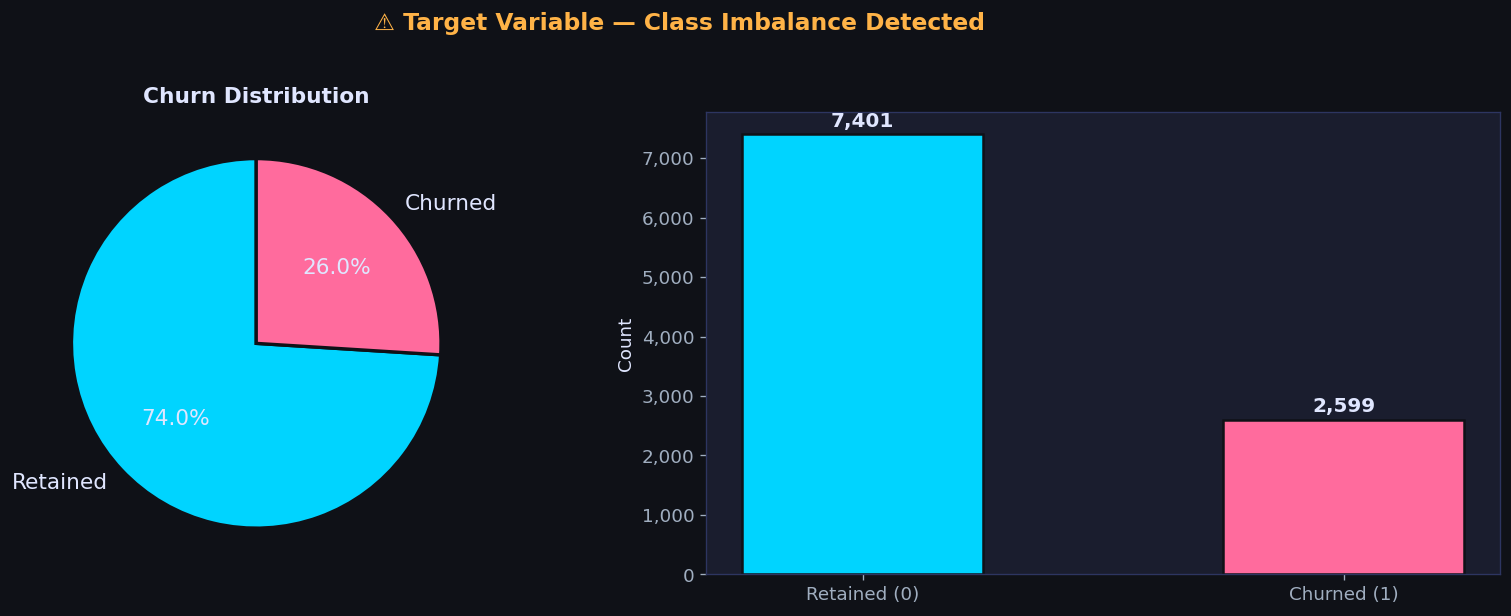

💡 Dataset is imbalanced — specialized handling required!


In [ ]:
# ── Target distribution ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cc = train_df['Churn'].value_counts()

axes[0].pie(cc, labels=['Retained','Churned'], autopct='%1.1f%%', startangle=90,
    colors=['#00d4ff','#ff6b9d'], wedgeprops={'edgecolor':'#0f1117','linewidth':2},
    textprops={'color':'#e0e6ff','fontsize':13})
axes[0].set_title('Churn Distribution')

bars = axes[1].bar(['Retained (0)','Churned (1)'], cc.values,
    color=['#00d4ff','#ff6b9d'], edgecolor='#0f1117', linewidth=1.5, width=0.5)
for bar, val in zip(bars, cc.values):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+60,
        f'{val:,}', ha='center', va='bottom', color='#e0e6ff', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Count')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{int(x):,}'))

plt.suptitle(' Target Variable — Class Imbalance Detected', fontsize=14,
    color='#ffb347', y=1.02, fontweight='bold')
plt.tight_layout()
plt.savefig('churn_distribution.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()
print(" Dataset is imbalanced — specialized handling required!")


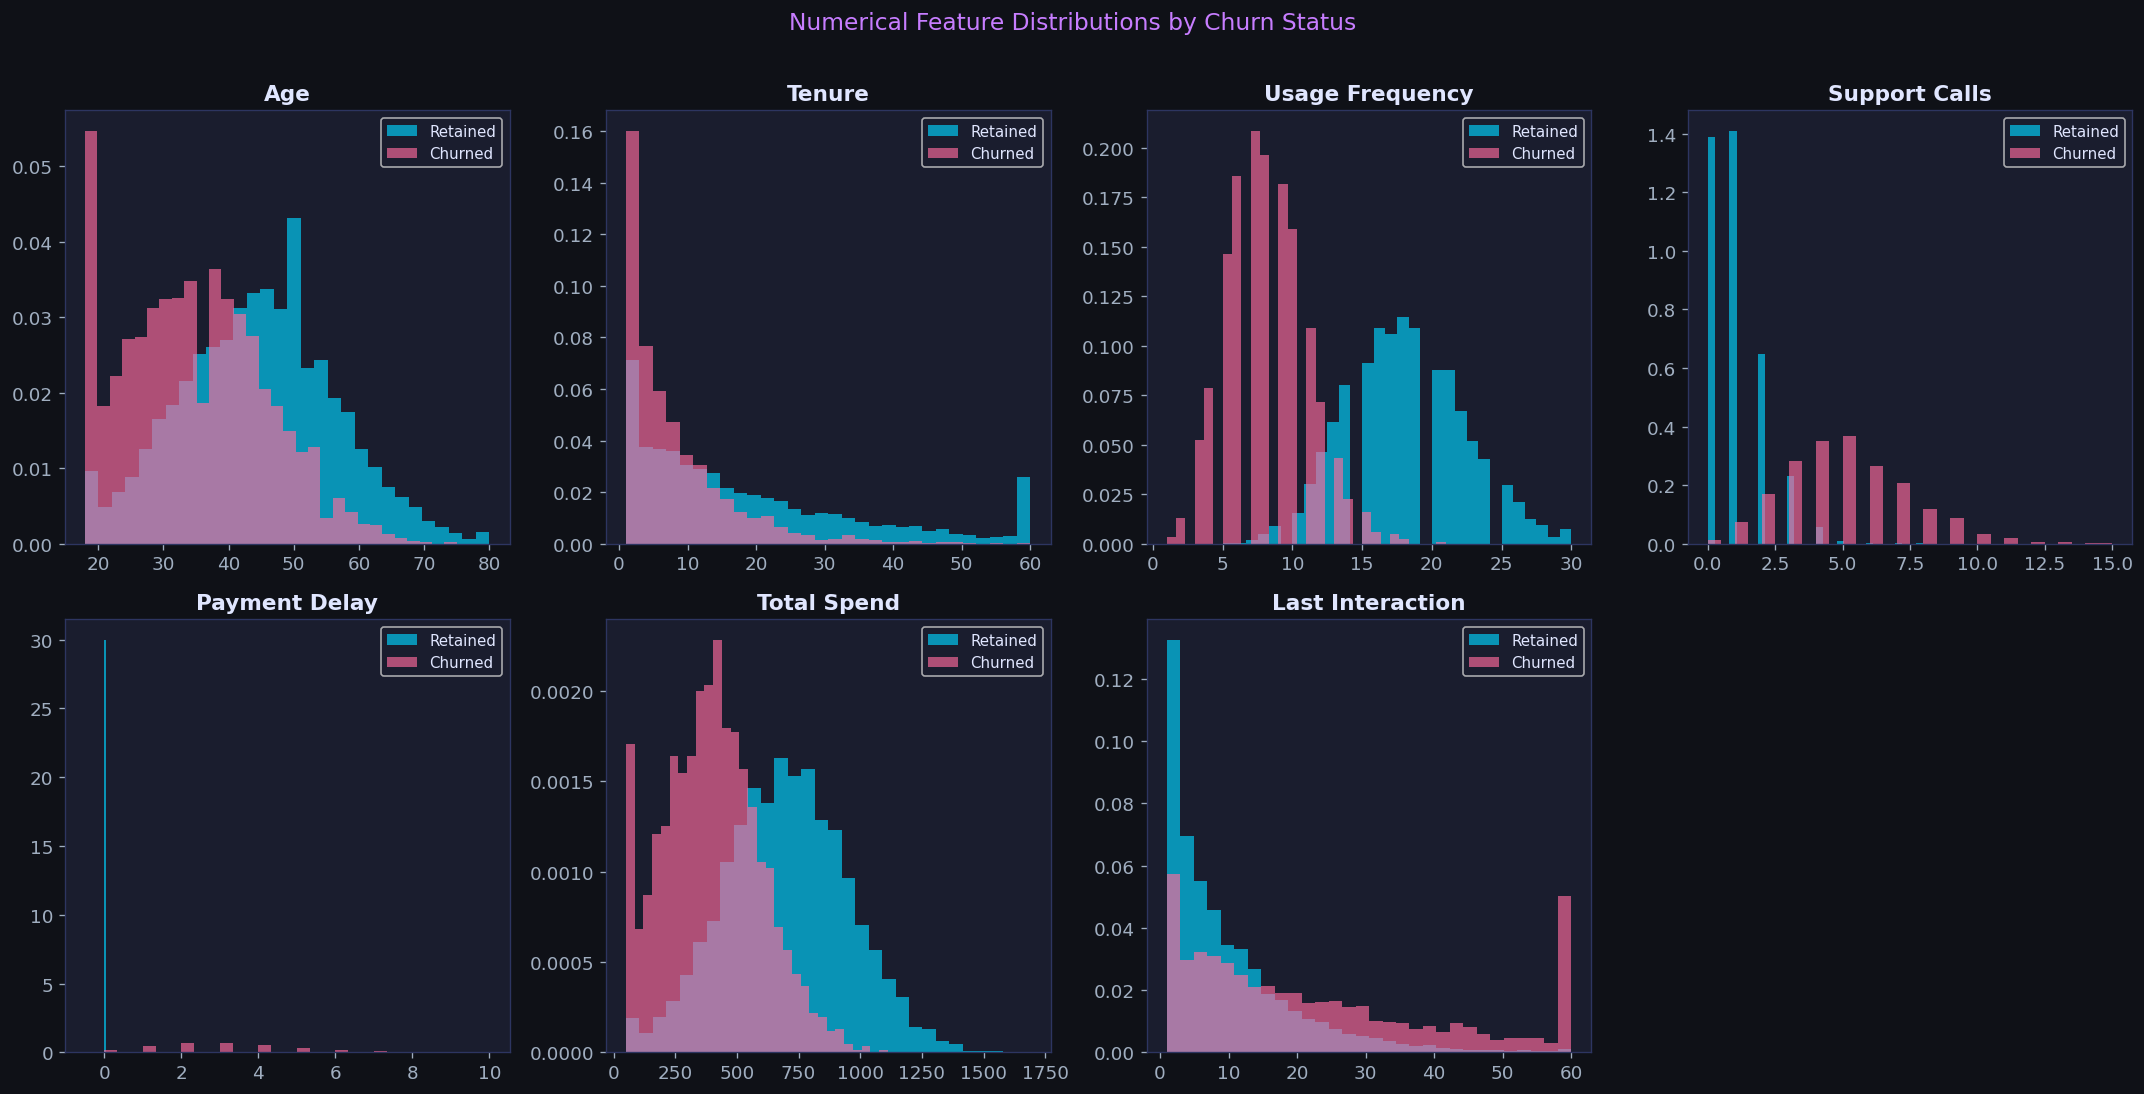

In [6]:
# ── Numerical feature distributions by churn ─────────────────────────────────
NUM_EDA = ['Age','Tenure','Usage Frequency','Support Calls',
           'Payment Delay','Total Spend','Last Interaction']
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes_flat = axes.flatten()

for i, col in enumerate(NUM_EDA):
    for cv, color, lbl in [(0,'#00d4ff','Retained'),(1,'#ff6b9d','Churned')]:
        axes_flat[i].hist(train_df[train_df['Churn']==cv][col].dropna(),
            bins=30, alpha=0.65, color=color, label=lbl, density=True)
    axes_flat[i].set_title(col); axes_flat[i].legend(fontsize=9)

axes_flat[-1].axis('off')   # hide the 8th empty subplot
plt.suptitle('Numerical Feature Distributions by Churn Status',
    fontsize=14, y=1.01, color='#c77dff')
plt.tight_layout()
plt.savefig('feature_distributions.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


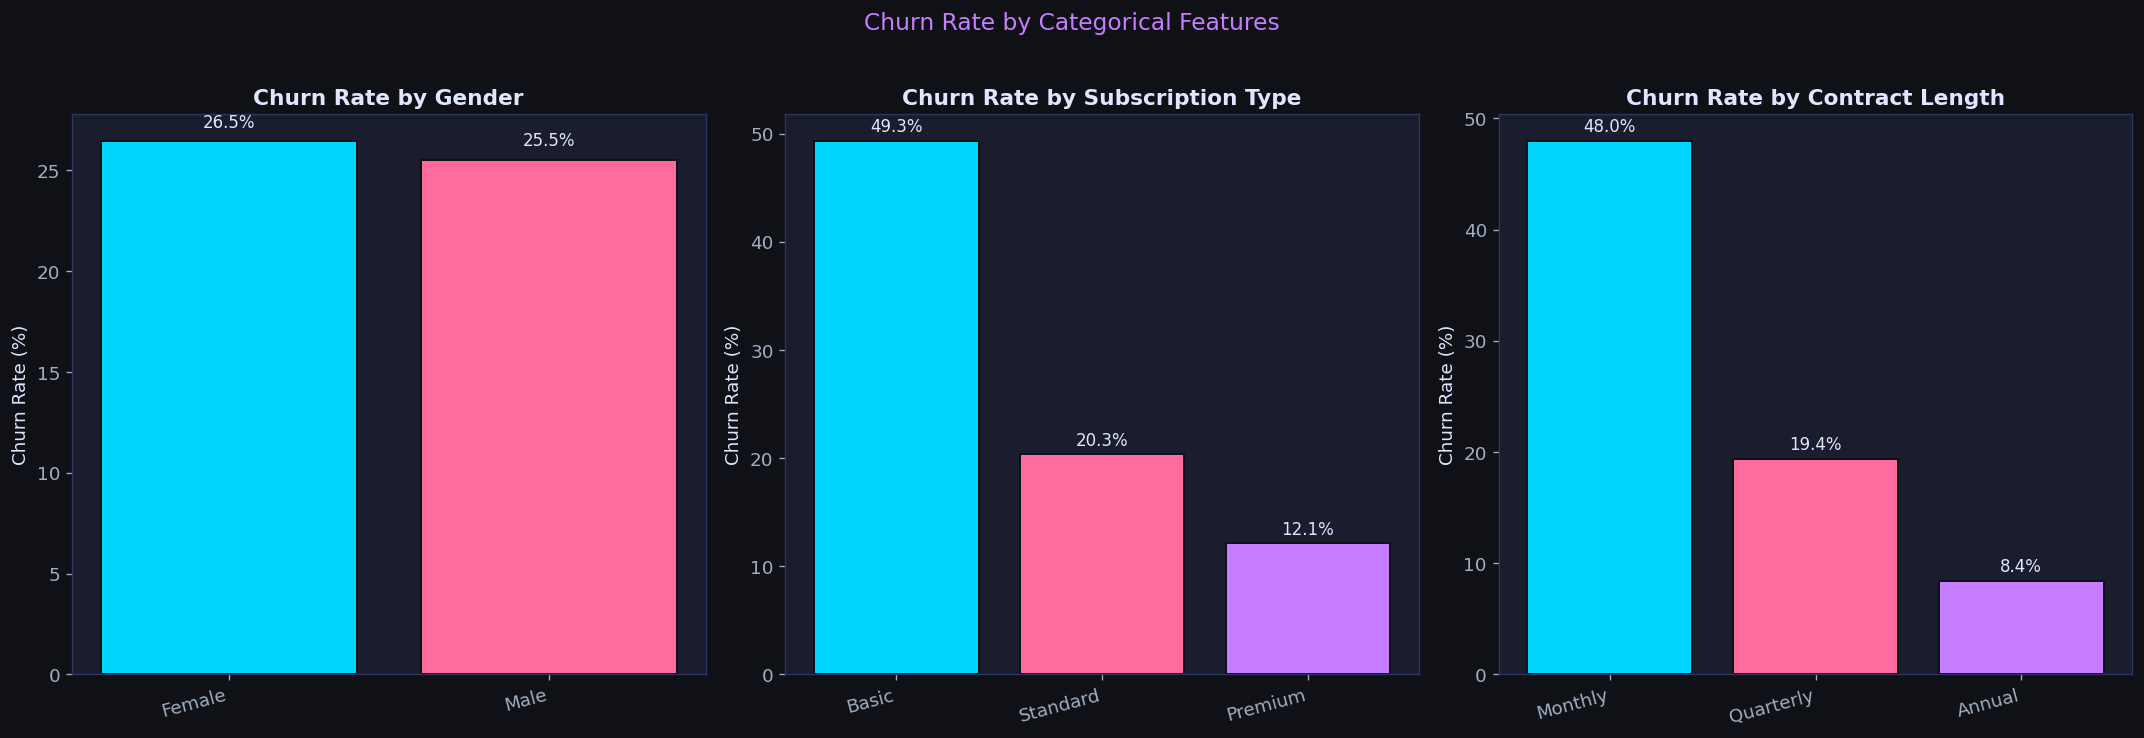

In [7]:
# ── Categorical features: churn rate per category ─────────────────────────────
CAT_EDA = ['Gender','Subscription Type','Contract Length']
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, col in enumerate(CAT_EDA):
    cr = train_df.groupby(col)['Churn'].mean().sort_values(ascending=False)
    bars = axes[i].bar(range(len(cr)), cr.values*100,
        color=PALETTE[:len(cr)], edgecolor='#0f1117', linewidth=1.2)
    axes[i].set_xticks(range(len(cr)))
    axes[i].set_xticklabels(cr.index, rotation=15, ha='right', fontsize=11)
    axes[i].set_title(f'Churn Rate by {col}')
    axes[i].set_ylabel('Churn Rate (%)')
    for bar, val in zip(bars, cr.values):
        axes[i].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{val*100:.1f}%', ha='center', va='bottom', fontsize=10, color='#e0e6ff')

plt.suptitle('Churn Rate by Categorical Features', fontsize=14, y=1.02, color='#c77dff')
plt.tight_layout()
plt.savefig('categorical_churn_rates.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


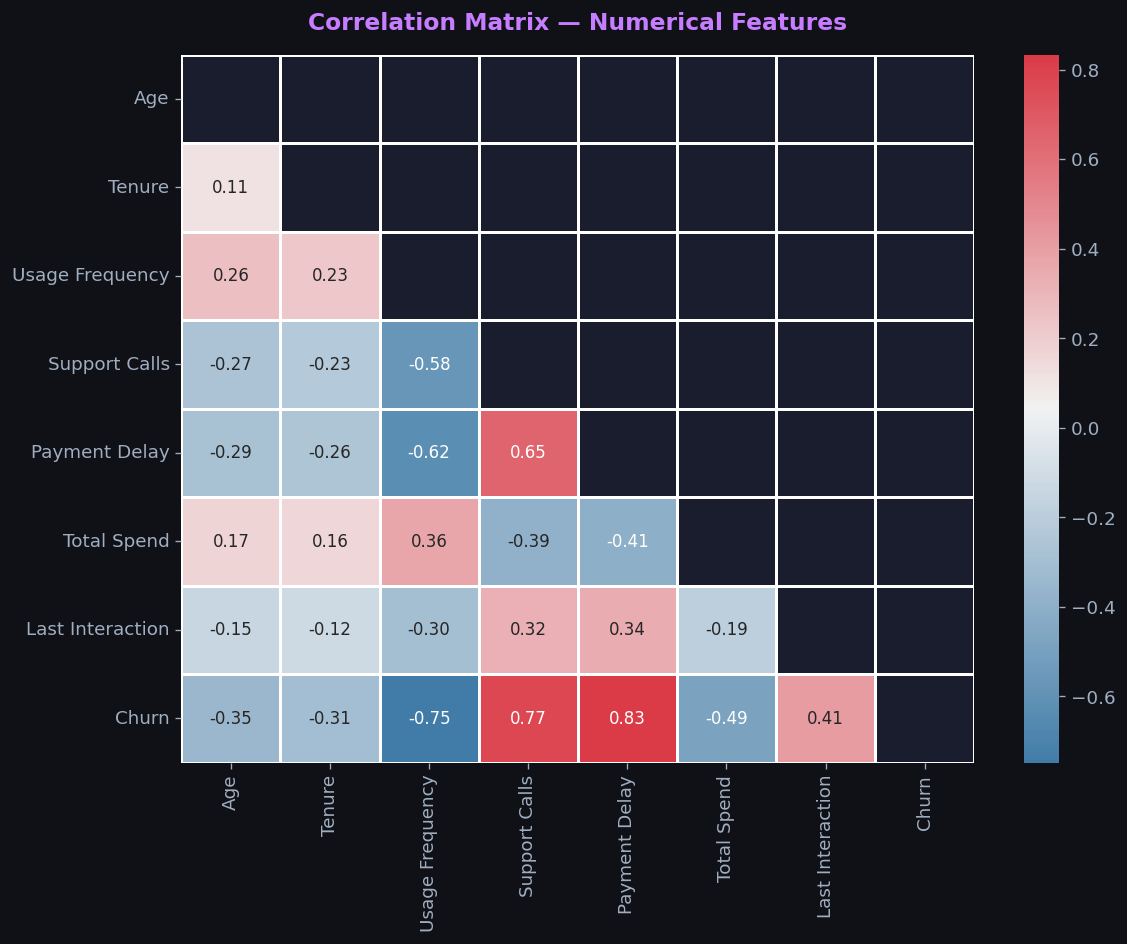


Top correlations with Churn:
Payment Delay       0.833341
Support Calls       0.771596
Usage Frequency    -0.748274
Total Spend        -0.488539
Last Interaction    0.412477
Age                -0.347635
Tenure             -0.305881


In [8]:
# ── Correlation heatmap ───────────────────────────────────────────────────────
num_data = train_df[NUM_EDA + ['Churn']].dropna()
corr = num_data.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', linewidths=0.8,
    cmap=sns.diverging_palette(240, 10, as_cmap=True),
    ax=ax, annot_kws={'size':10})
ax.set_title('Correlation Matrix — Numerical Features', fontsize=14, pad=15, color='#c77dff')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()

print("\nTop correlations with Churn:")
print(corr['Churn'].drop('Churn').sort_values(key=abs, ascending=False).to_string())


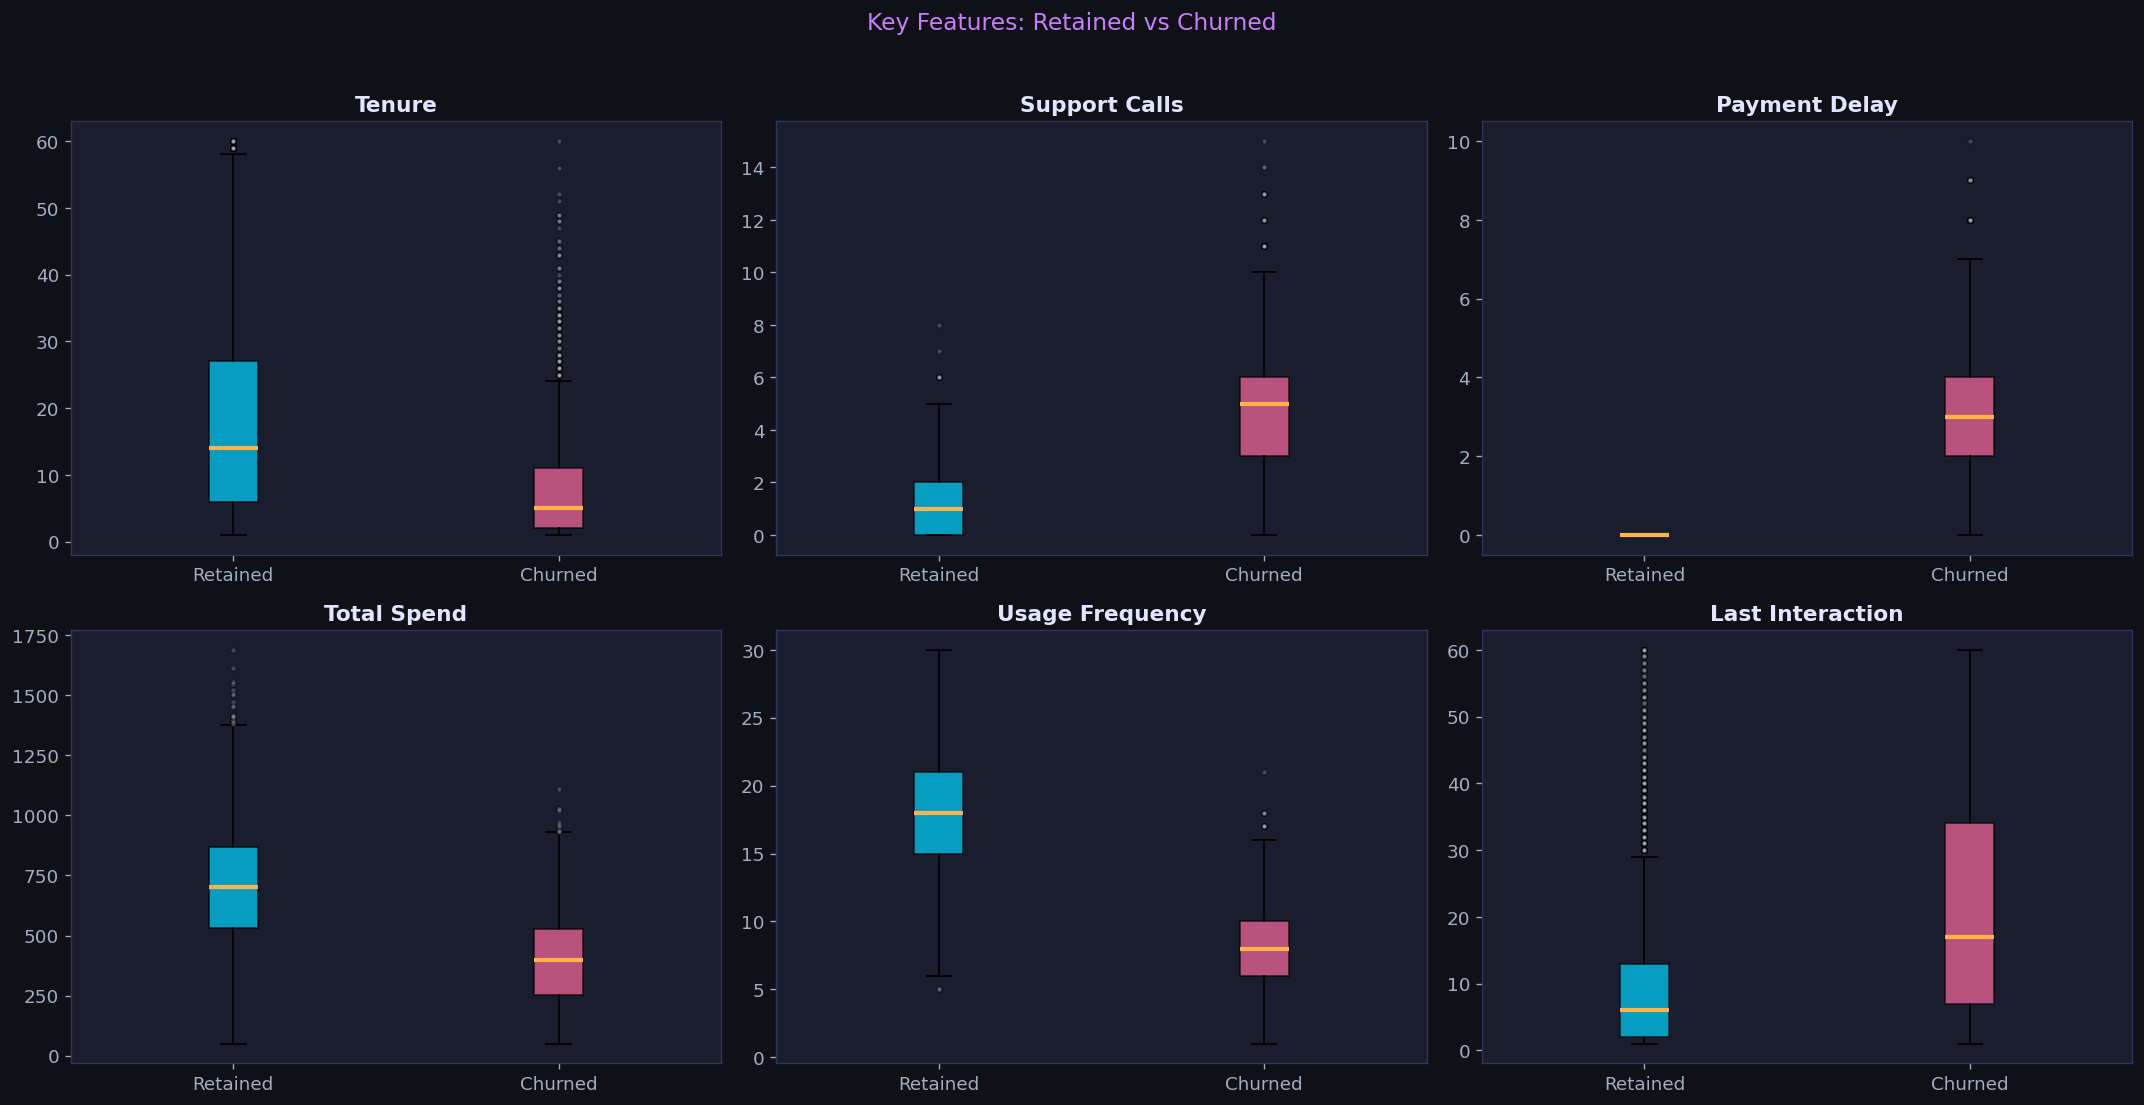

In [9]:
# ── Boxplots: key numeric features vs churn ───────────────────────────────────
key_cols = ['Tenure','Support Calls','Payment Delay','Total Spend','Usage Frequency','Last Interaction']
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

for ax, col in zip(axes.flatten(), key_cols):
    d0 = train_df[train_df['Churn']==0][col].dropna()
    d1 = train_df[train_df['Churn']==1][col].dropna()
    bp = ax.boxplot([d0, d1], patch_artist=True,
        medianprops=dict(color='#ffb347', linewidth=2.5),
        flierprops=dict(marker='o', markerfacecolor='#a0aec0', markersize=3, alpha=0.3))
    bp['boxes'][0].set_facecolor('#00d4ff'); bp['boxes'][0].set_alpha(0.7)
    bp['boxes'][1].set_facecolor('#ff6b9d'); bp['boxes'][1].set_alpha(0.7)
    ax.set_xticklabels(['Retained','Churned']); ax.set_title(col)

plt.suptitle('Key Features: Retained vs Churned', fontsize=14, y=1.02, color='#c77dff')
plt.tight_layout()
plt.savefig('boxplots.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


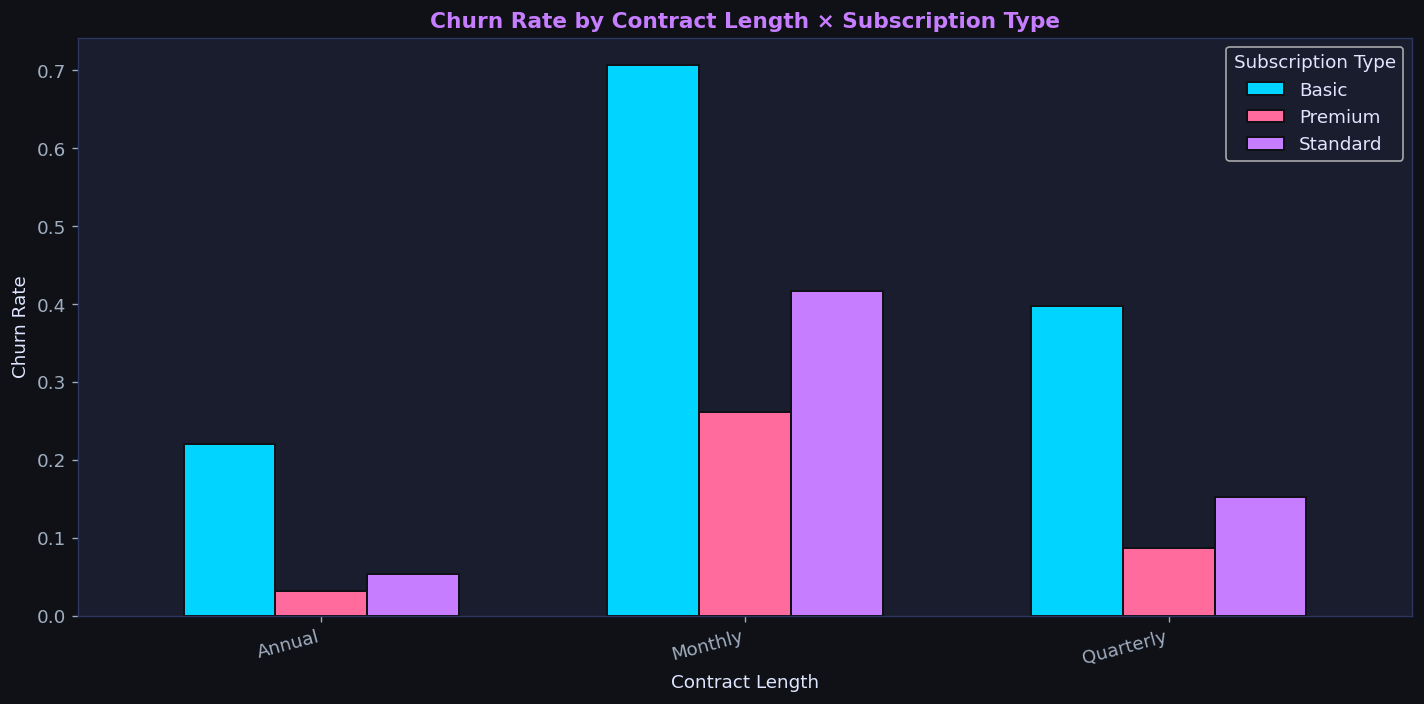

In [10]:
# ── Stacked bar: Churn rate by Contract Length × Subscription Type ────────────
pivot = train_df.groupby(['Contract Length','Subscription Type'])['Churn'].mean().unstack()
fig, ax = plt.subplots(figsize=(12, 6))
pivot.plot(kind='bar', ax=ax, color=PALETTE[:3], edgecolor='#0f1117', linewidth=1.2, width=0.65)
ax.set_ylabel('Churn Rate')
ax.set_title('Churn Rate by Contract Length × Subscription Type', color='#c77dff')
ax.legend(title='Subscription Type', facecolor='#1a1d2e', labelcolor='#e0e6ff')
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha='right')
plt.tight_layout()
plt.savefig('contract_subscription_churn.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


## 4.  Preprocessing & Feature Engineering
(preprocessor → SMOTE → model) and engineer
6 new features from the existing columns.

In [ ]:
# ── Column rename: spaces → underscores for convenience ──────────────────────
def clean_columns(df):
    return df.rename(columns={
        'Usage Frequency':   'UsageFrequency',
        'Support Calls':     'SupportCalls',
        'Payment Delay':     'PaymentDelay',
        'Subscription Type': 'SubscriptionType',
        'Contract Length':   'ContractLength',
        'Total Spend':       'TotalSpend',
        'Last Interaction':  'LastInteraction',
    })
train_df = clean_columns(train_df).drop(columns=['CustomerID'])
test_df  = clean_columns(test_df).drop(columns=['CustomerID'])
print("Cleaned columns:", list(train_df.columns))


Cleaned columns: ['Age', 'Gender', 'Tenure', 'UsageFrequency', 'SupportCalls', 'PaymentDelay', 'SubscriptionType', 'ContractLength', 'TotalSpend', 'LastInteraction', 'Churn']


In [ ]:
# ── Feature Engineering ───────────────────────────────────────────────────────
def engineer_features(df):
    df = df.copy()
    # Spend efficiency: how much does the customer spend relative to how long they've stayed?
    df['SpendPerMonth']      = df['TotalSpend'] / (df['Tenure'] + 1)
    # Engagement rate: how often do they use the product each month?
    df['EngagementRate']     = df['UsageFrequency'] / (df['Tenure'] + 1)
    # Risk composite: combines billing friction + support burden
    df['RiskScore']          = df['SupportCalls'] + df['PaymentDelay'] * 1.5
    # Loyalty flag: customers past 2 years rarely churn
    df['LongTermCustomer']   = (df['Tenure'] > 24).astype(int)
    # Inactivity flag: high last-interaction days = disengaged
    df['Inactive']           = (df['LastInteraction'] > 20).astype(int)
    # HighSpender flag
    df['HighSpender']        = (df['TotalSpend'] > df['TotalSpend'].median()).astype(int)
    return df
train_df = engineer_features(train_df)
test_df  = engineer_features(test_df)
print("Feature engineering complete")
print(f"   New: SpendPerMonth, EngagementRate, RiskScore, LongTermCustomer, Inactive, HighSpender")
print(f"   Total features: {train_df.shape[1] - 1}")

✅ Feature engineering complete
   New: SpendPerMonth, EngagementRate, RiskScore, LongTermCustomer, Inactive, HighSpender
   Total features: 16


In [13]:
TARGET = 'Churn'
X_full = train_df.drop(columns=[TARGET])
y_full = train_df[TARGET]
X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]

NUM_COLS = X_full.select_dtypes(include=['int64','float64']).columns.tolist()
CAT_COLS = X_full.select_dtypes(include=['object']).columns.tolist()

print(f"Numerical  ({len(NUM_COLS)}): {NUM_COLS}")
print(f"Categorical ({len(CAT_COLS)}): {CAT_COLS}")


Numerical  (13): ['Age', 'Tenure', 'UsageFrequency', 'SupportCalls', 'PaymentDelay', 'TotalSpend', 'LastInteraction', 'SpendPerMonth', 'EngagementRate', 'RiskScore', 'LongTermCustomer', 'Inactive', 'HighSpender']
Categorical (3): ['Gender', 'SubscriptionType', 'ContractLength']


In [14]:
# ── Preprocessor ─────────────────────────────────────────────────────────────
def make_preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('sc',  StandardScaler())
        ]), NUM_COLS),
        ('cat', Pipeline([
            ('imp', SimpleImputer(strategy='most_frequent')),
            ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), CAT_COLS)
    ], remainder='drop')

X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.15, random_state=SEED, stratify=y_full)
print(f"Train={X_train.shape}  Val={X_val.shape}  Test={X_test.shape}")
print(f"Churn rate — Train:{y_train.mean():.3f}  Val:{y_val.mean():.3f}  Test:{y_test.mean():.3f}")


Train=(8500, 16)  Val=(1500, 16)  Test=(3000, 16)
Churn rate — Train:0.260  Val:0.260  Test:0.277


## 5. Handling Imbalanced Data
Comparing 4 strategies using LightGBM as the base estimator.


In [ ]:
strategies = {
    'Class Weights': ImbPipeline([
        ('prep',  make_preprocessor()),
        ('model', LGBMClassifier(n_estimators=200, random_state=SEED,
                                 class_weight='balanced', verbose=-1))
    ]),
    'SMOTE': ImbPipeline([
        ('prep',  make_preprocessor()),
        ('smote', SMOTE(random_state=SEED)),
        ('model', LGBMClassifier(n_estimators=200, random_state=SEED, verbose=-1))
    ]),
    'RandomOverSampler': ImbPipeline([
        ('prep',  make_preprocessor()),
        ('ros',   RandomOverSampler(random_state=SEED)),
        ('model', LGBMClassifier(n_estimators=200, random_state=SEED, verbose=-1))
    ]),
    'RandomUnderSampler': ImbPipeline([
        ('prep',  make_preprocessor()),
        ('rus',   RandomUnderSampler(random_state=SEED)),
        ('model', LGBMClassifier(n_estimators=200, random_state=SEED, verbose=-1))
    ]),
}
resample_results = {}
for name, pipe in strategies.items():
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_val)[:,1]
    pred  = pipe.predict(X_val)
    resample_results[name] = {
        'AUC':       roc_auc_score(y_val, proba),
        'F1':        f1_score(y_val, pred),
        'Recall':    recall_score(y_val, pred),
        'Precision': precision_score(y_val, pred, zero_division=0),
        'Accuracy':  accuracy_score(y_val, pred),
    }
    r = resample_results[name]
    print(f"{name:22s}  AUC={r['AUC']:.4f}  F1={r['F1']:.4f}  Recall={r['Recall']:.4f}")

res_df = pd.DataFrame(resample_results).T.round(4).sort_values('F1', ascending=False)
print("\n", res_df.to_string())
print(f"\n✅ Best by F1: {res_df['F1'].idxmax()} — using SMOTE for model comparison.")

Class Weights           AUC=1.0000  F1=0.9974  Recall=0.9949


SMOTE                   AUC=1.0000  F1=0.9974  Recall=0.9949


RandomOverSampler       AUC=1.0000  F1=0.9974  Recall=0.9949
RandomUnderSampler      AUC=1.0000  F1=0.9962  Recall=0.9974

                     AUC      F1  Recall  Precision  Accuracy
Class Weights       1.0  0.9974  0.9949     1.0000    0.9987
SMOTE               1.0  0.9974  0.9949     1.0000    0.9987
RandomOverSampler   1.0  0.9974  0.9949     1.0000    0.9987
RandomUnderSampler  1.0  0.9962  0.9974     0.9949    0.9980

✅ Best by F1: Class Weights — using SMOTE for model comparison.


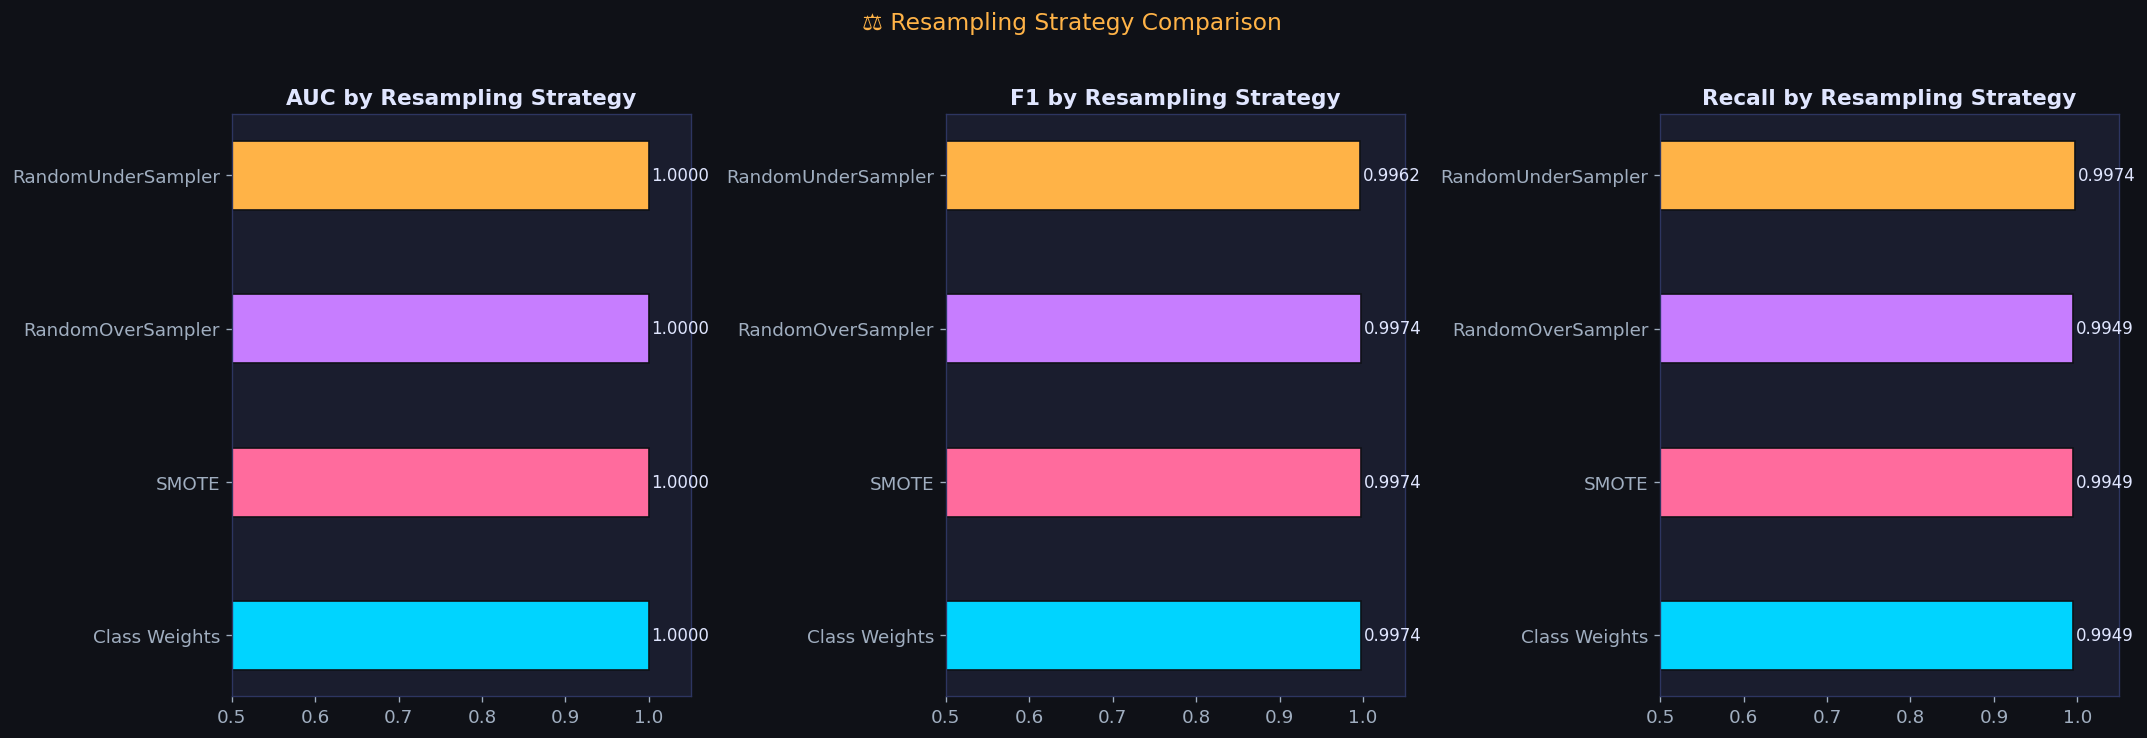

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, metric in zip(axes, ['AUC','F1','Recall']):
    vals  = res_df[metric].values
    names = res_df.index.tolist()
    bars  = ax.barh(names, vals, color=PALETTE[:4], edgecolor='#0f1117', height=0.45)
    ax.set_xlim(0.5, 1.05); ax.set_title(f'{metric} by Resampling Strategy')
    for bar, val in zip(bars, vals):
        ax.text(val+0.003, bar.get_y()+bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10, color='#e0e6ff')
plt.suptitle('⚖️ Resampling Strategy Comparison', fontsize=14, y=1.02, color='#ffb347')
plt.tight_layout()
plt.savefig('resampling_comparison.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


## 6. training multiple models & Comparison

In [ ]:
SCALE_POS = float((y_train==0).sum() / (y_train==1).sum())

model_defs = {
    'Logistic Regression': LogisticRegression(C=1.0, max_iter=1000,
        random_state=SEED, class_weight='balanced'),
    'Random Forest':       RandomForestClassifier(n_estimators=200,
        random_state=SEED, class_weight='balanced', n_jobs=-1),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=150,
        random_state=SEED),
    'XGBoost':             XGBClassifier(n_estimators=200, random_state=SEED,
        scale_pos_weight=SCALE_POS, eval_metric='logloss', verbosity=0),
    'LightGBM':            LGBMClassifier(n_estimators=200, random_state=SEED,
        class_weight='balanced', verbose=-1),
    'CatBoost':            CatBoostClassifier(iterations=200, random_seed=SEED,
        class_weights={0:1,1:3}, verbose=False),
    'SVM':                 SVC(C=1.0, kernel='rbf', probability=True,
        random_state=SEED, class_weight='balanced'),
}
# Wrap each in prep → SMOTE → model pipeline
model_pipes = {
    name: ImbPipeline([
        ('prep',  make_preprocessor()),
        ('smote', SMOTE(random_state=SEED)),
        ('model', m)
    ]) for name, m in model_defs.items()
}

results = {}; trained_pipes = {}
for name, pipe in model_pipes.items():
    print(f"Training {name}...", end='  ')
    pipe.fit(X_train, y_train)
    trained_pipes[name] = pipe
    proba = pipe.predict_proba(X_val)[:,1]
    pred  = pipe.predict(X_val)
    results[name] = {
        'Accuracy':  accuracy_score(y_val, pred),
        'Precision': precision_score(y_val, pred, zero_division=0),
        'Recall':    recall_score(y_val, pred),
        'F1':        f1_score(y_val, pred),
        'ROC-AUC':   roc_auc_score(y_val, proba),
        'Avg-Prec':  average_precision_score(y_val, proba),
    }
    r = results[name]
    print(f"✅  AUC={r['ROC-AUC']:.4f}  F1={r['F1']:.4f}  Recall={r['Recall']:.4f}")

results_df = pd.DataFrame(results).T.round(4).sort_values('ROC-AUC', ascending=False)
print("\n", results_df.to_string())


Training Logistic Regression...  ✅  AUC=1.0000  F1=0.9974  Recall=0.9974
Training Random Forest...  

✅  AUC=1.0000  F1=0.9974  Recall=0.9949
Training Gradient Boosting...  

✅  AUC=1.0000  F1=0.9974  Recall=0.9949
Training XGBoost...  

✅  AUC=1.0000  F1=0.9974  Recall=0.9949
Training LightGBM...  

✅  AUC=1.0000  F1=0.9974  Recall=0.9949
Training CatBoost...  

✅  AUC=1.0000  F1=0.9974  Recall=0.9974
Training SVM...  

✅  AUC=1.0000  F1=0.9987  Recall=0.9974

                      Accuracy  Precision  Recall      F1  ROC-AUC  Avg-Prec
Logistic Regression    0.9987     0.9974  0.9974  0.9974      1.0       1.0
Random Forest          0.9987     1.0000  0.9949  0.9974      1.0       1.0
Gradient Boosting      0.9987     1.0000  0.9949  0.9974      1.0       1.0
XGBoost                0.9987     1.0000  0.9949  0.9974      1.0       1.0
LightGBM               0.9987     1.0000  0.9949  0.9974      1.0       1.0
CatBoost               0.9987     0.9974  0.9974  0.9974      1.0       1.0
SVM                    0.9993     1.0000  0.9974  0.9987      1.0       1.0


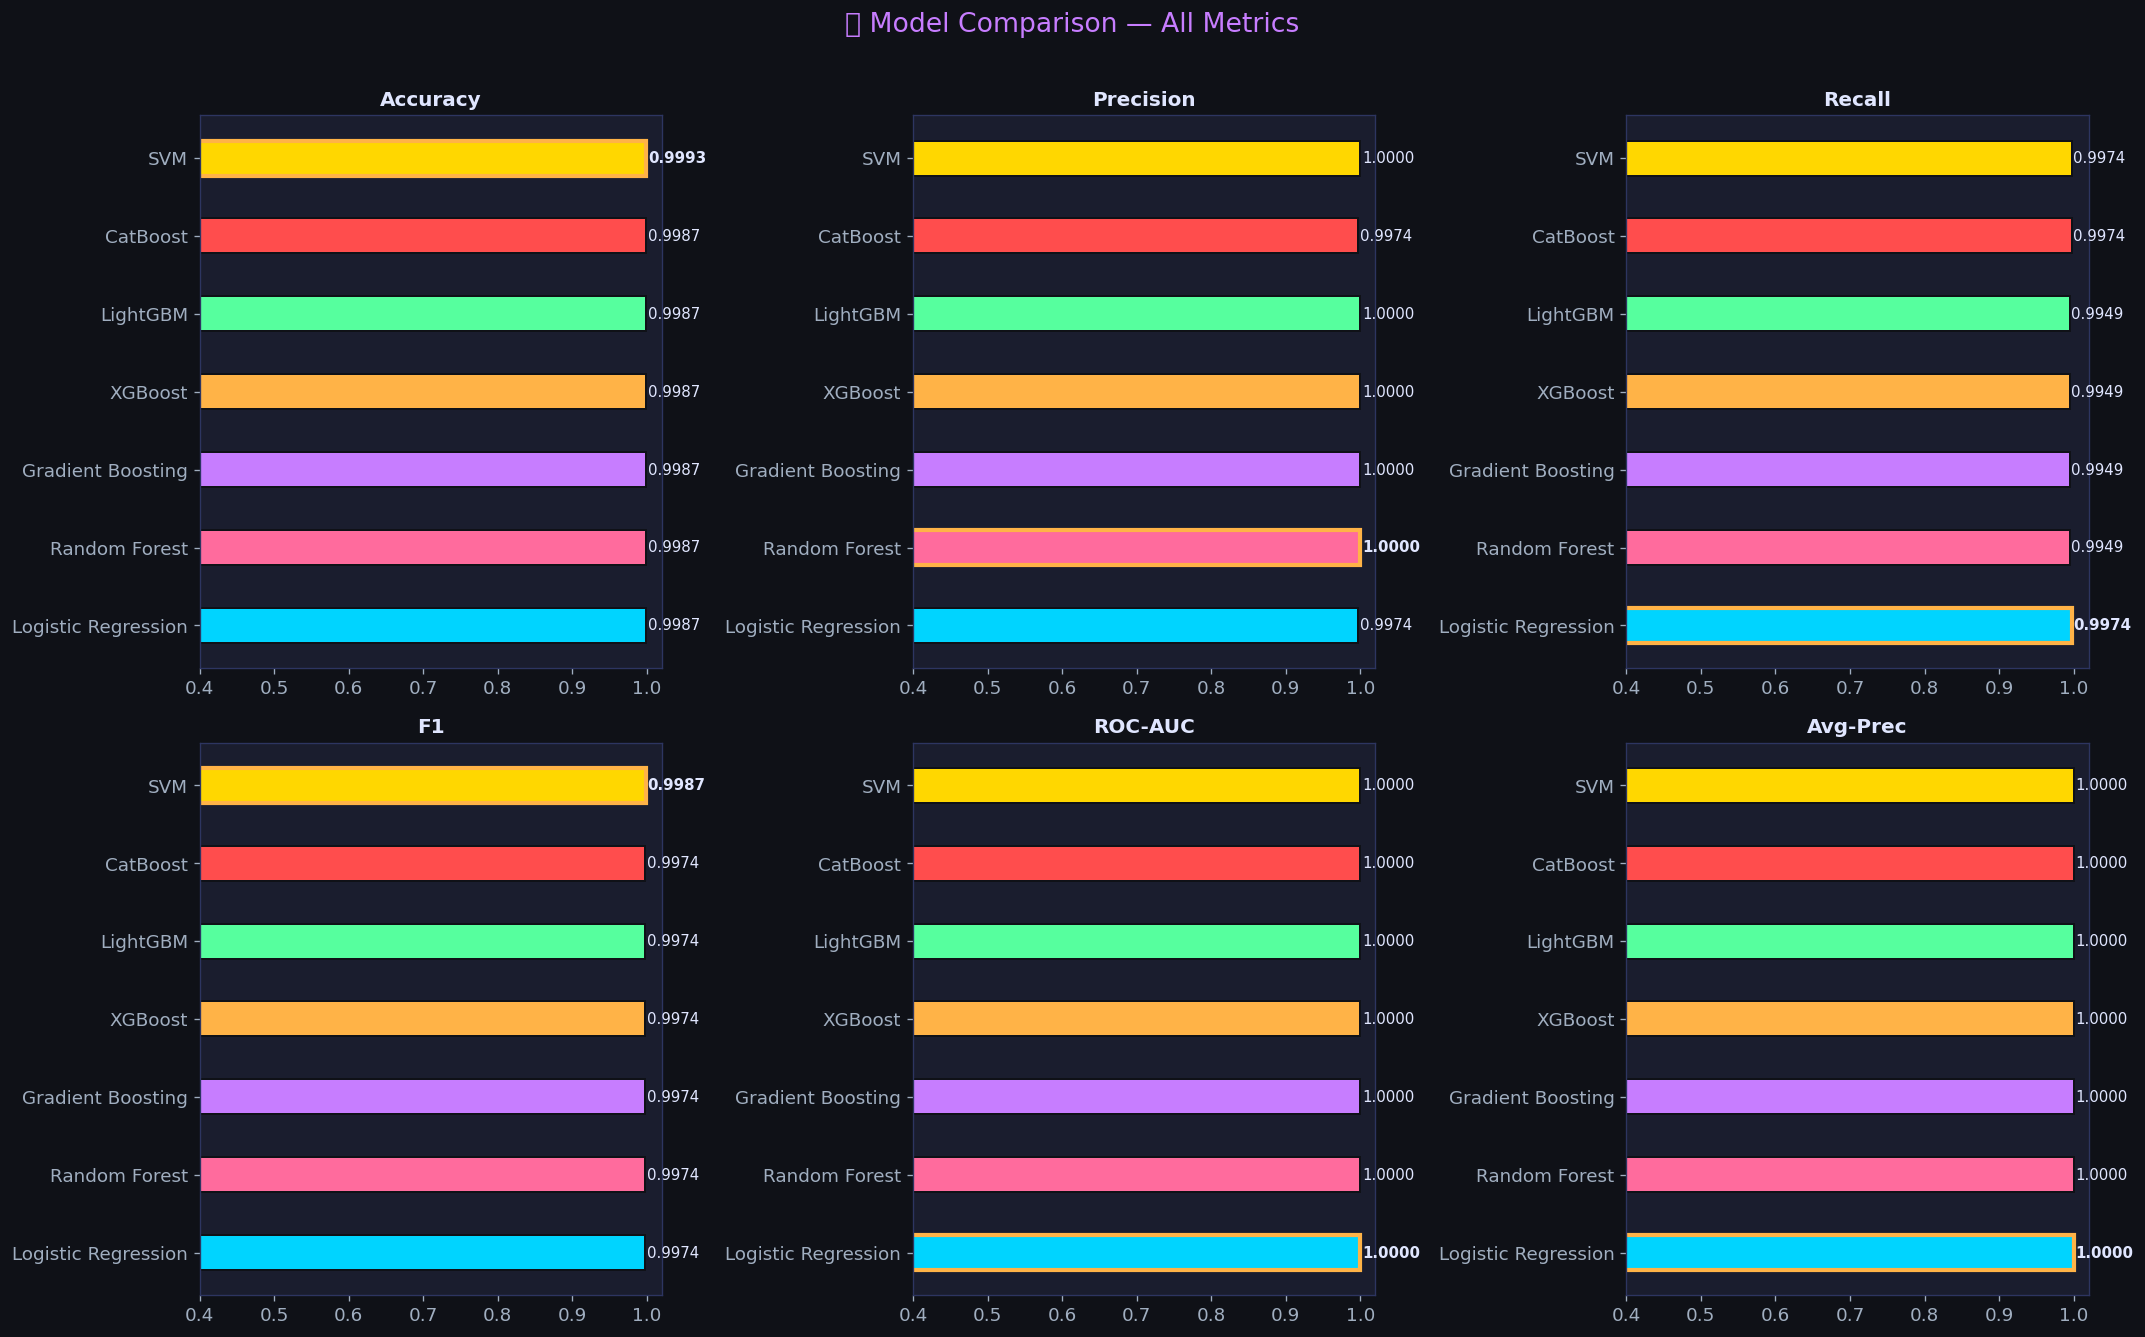

In [18]:
# ── Model comparison bar charts ───────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
model_names = results_df.index.tolist()
cmap = dict(zip(model_names, PALETTE))

for ax, metric in zip(axes.flatten(), ['Accuracy','Precision','Recall','F1','ROC-AUC','Avg-Prec']):
    vals  = results_df[metric].values
    bars  = ax.barh(model_names, vals,
        color=[cmap.get(m,'#888') for m in model_names],
        edgecolor='#0f1117', height=0.45, linewidth=1.2)
    ax.set_xlim(0.4, 1.02); ax.set_title(metric, fontsize=12, fontweight='bold')
    bi = np.argmax(vals)
    for j,(bar,val) in enumerate(zip(bars, vals)):
        ax.text(val+0.002, bar.get_y()+bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=9, color='#e0e6ff',
            fontweight='bold' if j==bi else 'normal')
    bars[bi].set_edgecolor('#ffb347'); bars[bi].set_linewidth(2.5)

plt.suptitle('🏆 Model Comparison — All Metrics', fontsize=16, y=1.01, color='#c77dff')
plt.tight_layout()
plt.savefig('model_comparison.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


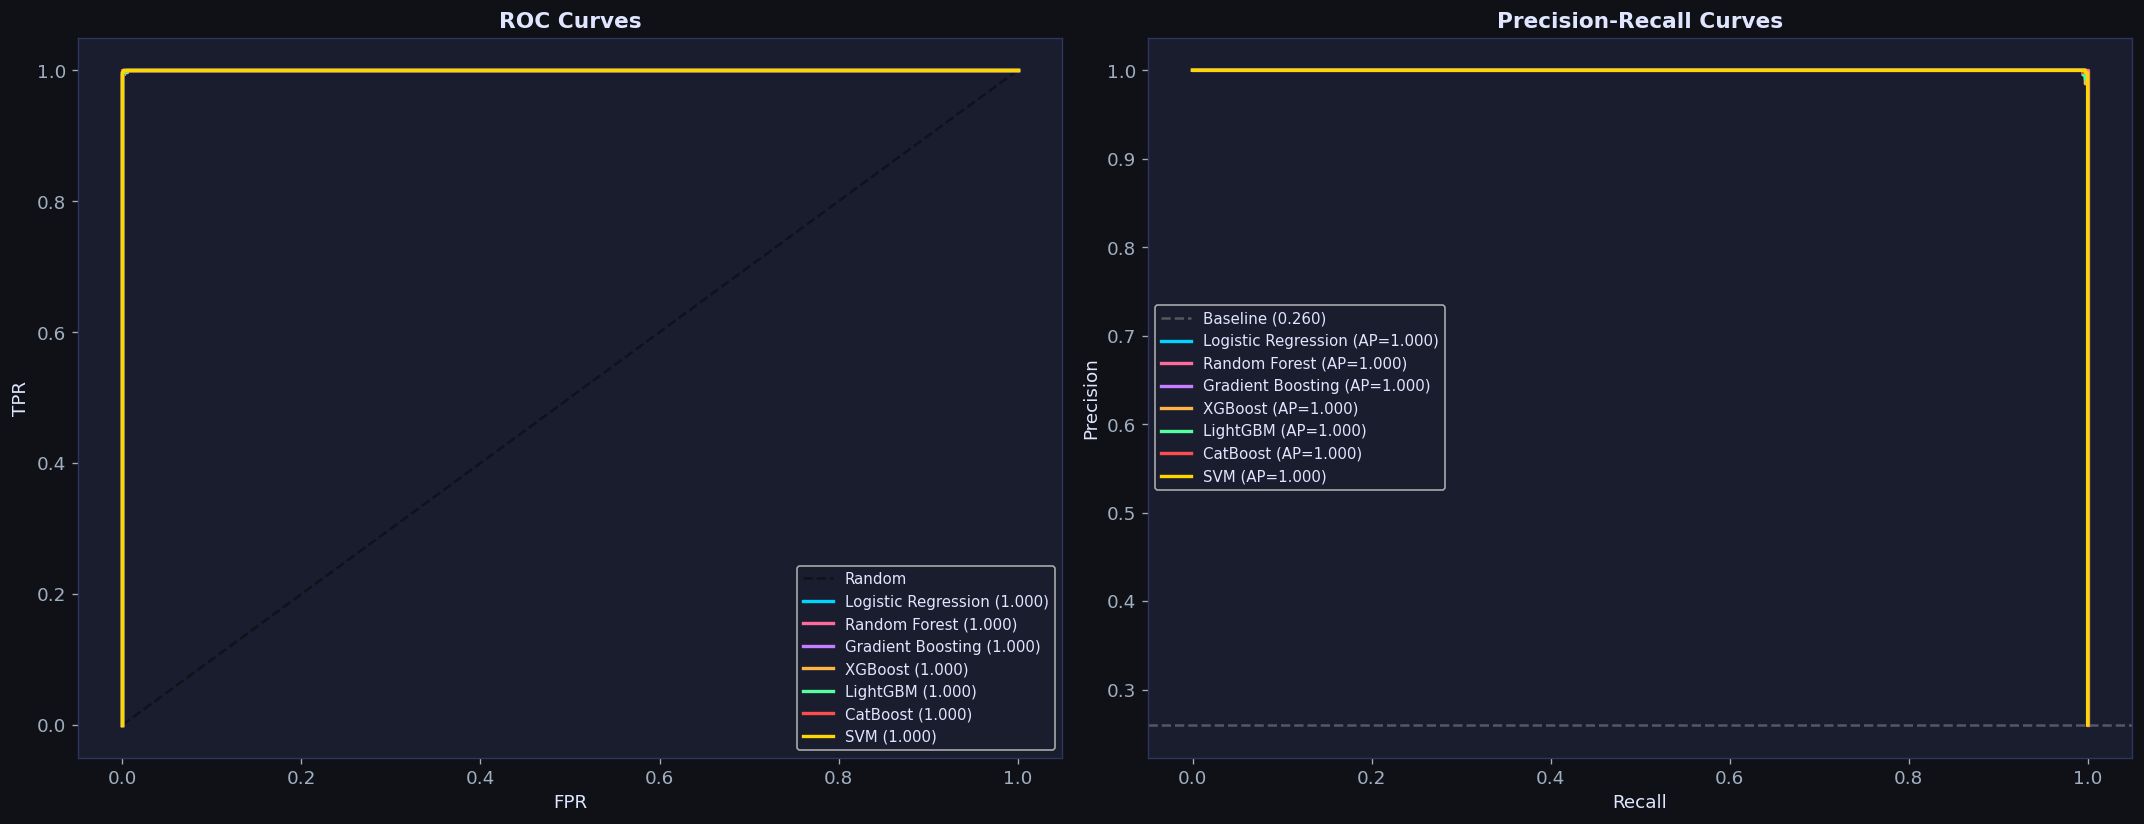

In [19]:
# ── ROC + PR curves ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].plot([0,1],[0,1],'k--',alpha=0.4,lw=1.5,label='Random')
axes[1].axhline(y_val.mean(), color='gray', ls='--', alpha=0.6,
    label=f'Baseline ({y_val.mean():.3f})')

for i,(name,pipe) in enumerate(trained_pipes.items()):
    proba = pipe.predict_proba(X_val)[:,1]; c = PALETTE[i%len(PALETTE)]
    fpr,tpr,_ = roc_curve(y_val, proba)
    axes[0].plot(fpr, tpr, lw=2, color=c,
        label=f'{name} ({roc_auc_score(y_val,proba):.3f})')
    prec,rec,_ = precision_recall_curve(y_val, proba)
    axes[1].plot(rec, prec, lw=2, color=c,
        label=f'{name} (AP={average_precision_score(y_val,proba):.3f})')

for ax,xl,yl,ttl in [(axes[0],'FPR','TPR','ROC Curves'),
                     (axes[1],'Recall','Precision','Precision-Recall Curves')]:
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(ttl)
    ax.legend(fontsize=9, facecolor='#1a1d2e', labelcolor='#e0e6ff')

plt.tight_layout()
plt.savefig('roc_pr_curves.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


## 7. Hyperparameter Tuning — LightGBM



In [20]:
param_dist = {
    'model__n_estimators':     [200, 300, 400, 500],
    'model__max_depth':        [4, 5, 6, 7, 8, -1],
    'model__learning_rate':    [0.03, 0.05, 0.08, 0.1, 0.15],
    'model__num_leaves':       [20, 31, 40, 50, 64],
    'model__subsample':        [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'model__min_child_samples':[10, 20, 30, 50],
    'model__reg_alpha':        [0, 0.01, 0.1, 0.5],
    'model__reg_lambda':       [0, 0.01, 0.1, 0.5, 1.0],
}

tune_pipe = ImbPipeline([
    ('prep',  make_preprocessor()),
    ('smote', SMOTE(random_state=SEED)),
    ('model', LGBMClassifier(random_state=SEED, class_weight='balanced', verbose=-1))
])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = RandomizedSearchCV(tune_pipe, param_dist, n_iter=30, scoring='roc_auc',
    cv=cv5, n_jobs=-1, random_state=SEED, verbose=1)

print("🔍 Running RandomizedSearchCV (30 iterations × 5-fold)…")
search.fit(X_train, y_train)

print(f"\n✅ Best CV ROC-AUC: {search.best_score_:.4f}")
print("Best parameters:")
for k,v in search.best_params_.items():
    print(f"  {k:35s}: {v}")


🔍 Running RandomizedSearchCV (30 iterations × 5-fold)…
Fitting 5 folds for each of 30 candidates, totalling 150 fits



✅ Best CV ROC-AUC: 0.9999
Best parameters:
  model__subsample                   : 1.0
  model__reg_lambda                  : 0.5
  model__reg_alpha                   : 0.5
  model__num_leaves                  : 50
  model__n_estimators                : 500
  model__min_child_samples           : 10
  model__max_depth                   : 8
  model__learning_rate               : 0.1
  model__colsample_bytree            : 1.0


In [21]:
best_pipe = search.best_estimator_
vp = best_pipe.predict_proba(X_val)[:,1]
vd = best_pipe.predict(X_val)
print("Tuned LightGBM — Validation:")
print(f"  AUC={roc_auc_score(y_val,vp):.4f}  F1={f1_score(y_val,vd):.4f}  "
      f"Recall={recall_score(y_val,vd):.4f}  "
      f"Precision={precision_score(y_val,vd,zero_division=0):.4f}")


Tuned LightGBM — Validation:
  AUC=1.0000  F1=0.9974  Recall=0.9949  Precision=1.0000


## 8. Final Evaluation & Threshold Optimization

Optimal threshold: 0.34
  F1=0.9976  Recall=0.9964  Precision=0.9988


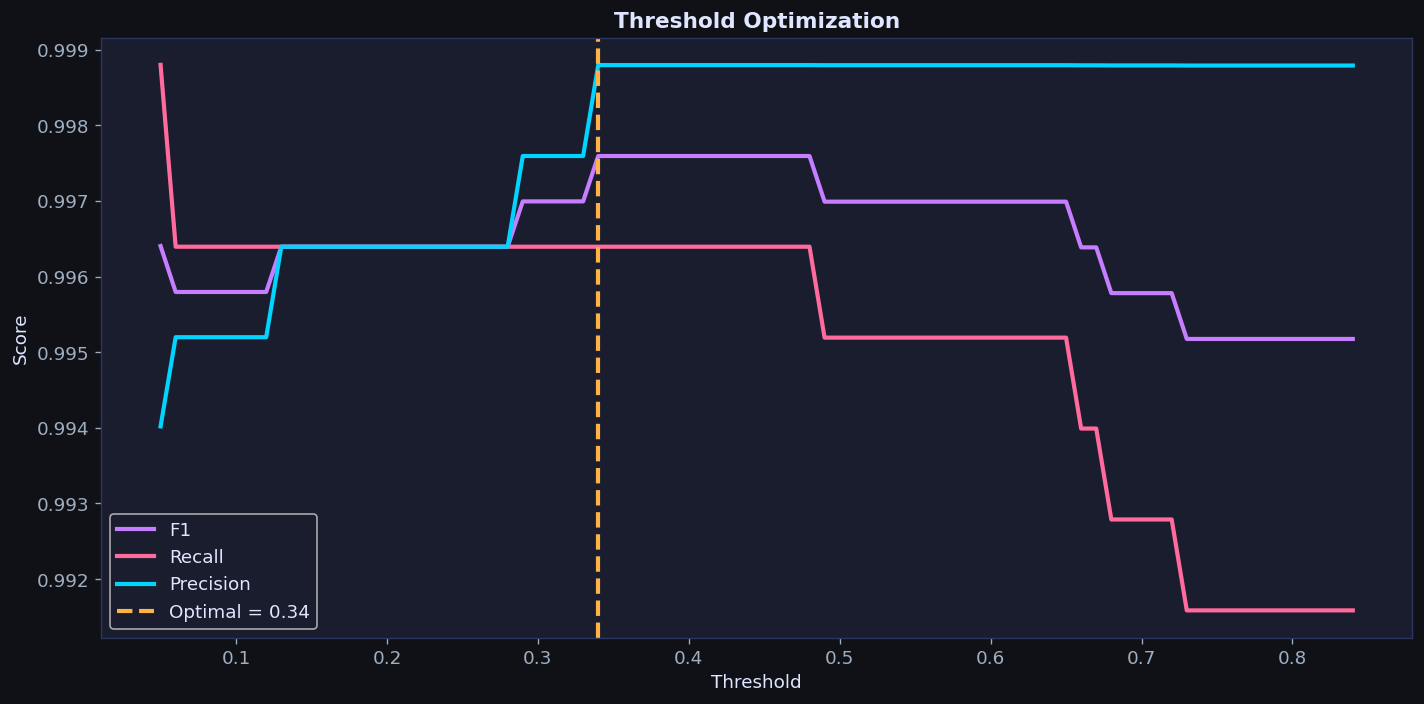

In [22]:
test_proba = best_pipe.predict_proba(X_test)[:,1]
thresholds = np.arange(0.05, 0.85, 0.01)
f1s, recs, pres = [], [], []
for t in thresholds:
    p = (test_proba >= t).astype(int)
    f1s.append(f1_score(y_test, p, zero_division=0))
    recs.append(recall_score(y_test, p, zero_division=0))
    pres.append(precision_score(y_test, p, zero_division=0))

OPT_T = float(thresholds[np.argmax(f1s)])
print(f"Optimal threshold: {OPT_T:.2f}")
print(f"  F1={max(f1s):.4f}  "
      f"Recall={recs[np.argmax(f1s)]:.4f}  "
      f"Precision={pres[np.argmax(f1s)]:.4f}")

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(thresholds, f1s,  color='#c77dff', lw=2.5, label='F1')
ax.plot(thresholds, recs, color='#ff6b9d', lw=2.5, label='Recall')
ax.plot(thresholds, pres, color='#00d4ff', lw=2.5, label='Precision')
ax.axvline(OPT_T, color='#ffb347', lw=2.5, ls='--',
    label=f'Optimal = {OPT_T:.2f}')
ax.set_xlabel('Threshold'); ax.set_ylabel('Score')
ax.set_title('Threshold Optimization'); ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('threshold_optimization.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


In [23]:
pred_def = (test_proba >= 0.50).astype(int)
pred_opt = (test_proba >= OPT_T).astype(int)
print("="*60)
for label, pred in [('Default (0.50)', pred_def),
                    (f'Optimal ({OPT_T:.2f})', pred_opt)]:
    print(f"\n── Threshold: {label} ──")
    print(f"  AUC={roc_auc_score(y_test,test_proba):.4f}  "
          f"F1={f1_score(y_test,pred):.4f}  "
          f"Recall={recall_score(y_test,pred):.4f}  "
          f"Precision={precision_score(y_test,pred,zero_division=0):.4f}")
    print(classification_report(y_test, pred, target_names=['Retained','Churned']))



── Threshold: Default (0.50) ──
  AUC=1.0000  F1=0.9970  Recall=0.9952  Precision=0.9988
              precision    recall  f1-score   support

    Retained       1.00      1.00      1.00      2168
     Churned       1.00      1.00      1.00       832

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000


── Threshold: Optimal (0.34) ──
  AUC=1.0000  F1=0.9976  Recall=0.9964  Precision=0.9988
              precision    recall  f1-score   support

    Retained       1.00      1.00      1.00      2168
     Churned       1.00      1.00      1.00       832

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000



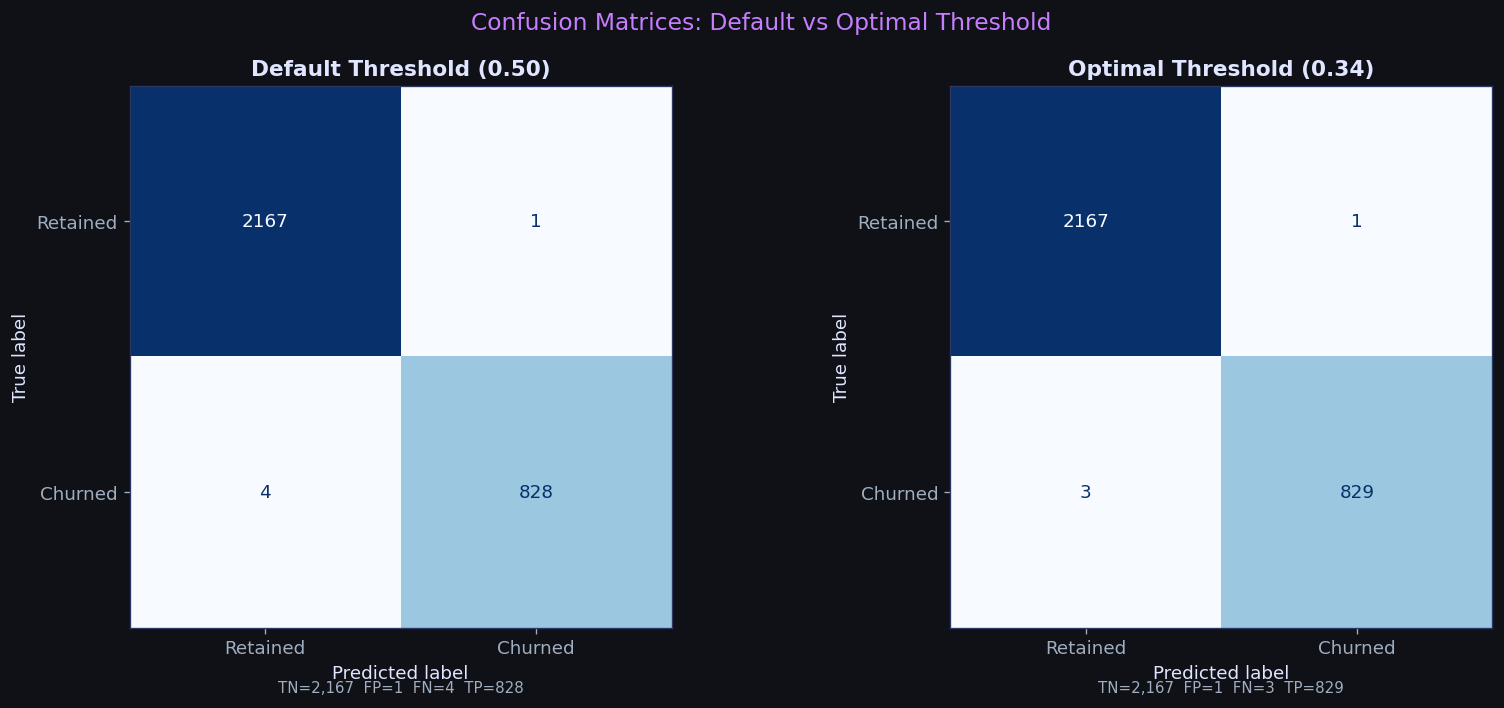

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax,(pred,title) in zip(axes,[
        (pred_def, 'Default Threshold (0.50)'),
        (pred_opt, f'Optimal Threshold ({OPT_T:.2f})')]):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=['Retained','Churned']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(title)
    tn,fp,fn,tp = cm.ravel()
    ax.text(0.5,-0.12,f'TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}',
        transform=ax.transAxes, ha='center', fontsize=9, color='#a0aec0')
plt.suptitle('Confusion Matrices: Default vs Optimal Threshold',
    fontsize=14, color='#c77dff')
plt.tight_layout()
plt.savefig('confusion_matrices.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


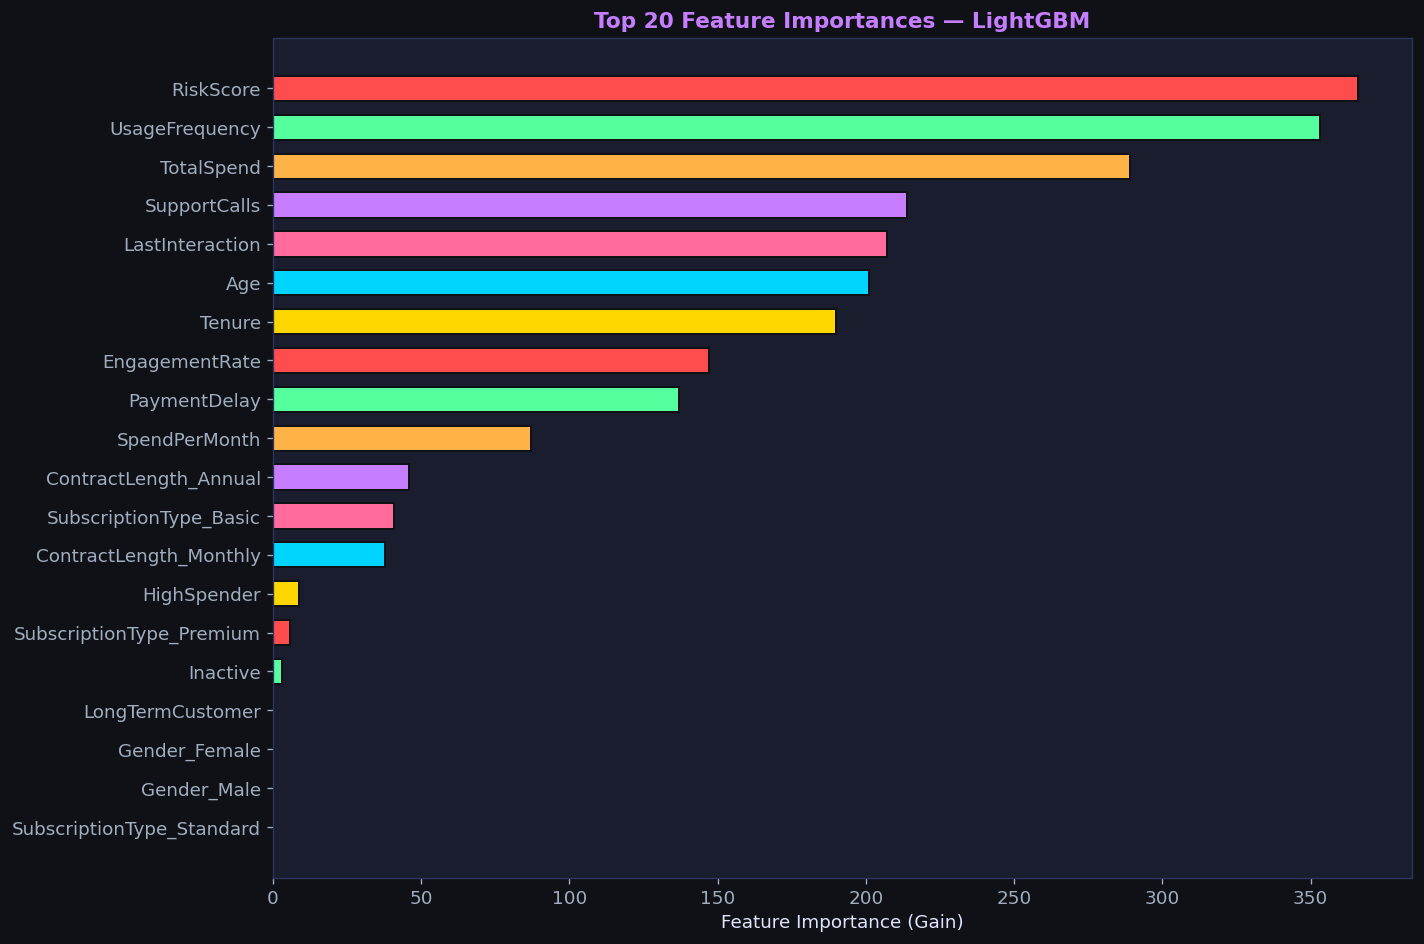

In [25]:
# ── Feature importance ────────────────────────────────────────────────────────
lgbm_step = best_pipe.named_steps['model']
prep_step  = best_pipe.named_steps['prep']
ohe        = prep_step.named_transformers_['cat']['enc']
all_feat_names = NUM_COLS + list(ohe.get_feature_names_out(CAT_COLS))

n = min(len(lgbm_step.feature_importances_), len(all_feat_names))
feat_imp = pd.Series(
    lgbm_step.feature_importances_[:n],
    index=all_feat_names[:n]
).sort_values(ascending=False)
top20 = feat_imp.head(20)

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(top20.index[::-1], top20.values[::-1],
    color=[PALETTE[i%len(PALETTE)] for i in range(len(top20))],
    edgecolor='#0f1117', linewidth=1.2, height=0.65)
ax.set_xlabel('Feature Importance (Gain)')
ax.set_title('Top 20 Feature Importances — LightGBM', color='#c77dff')
plt.tight_layout()
plt.savefig('feature_importance.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


## 9. SHAP Explainability

In [26]:
X_test_proc = prep_step.transform(X_test)
n_f = X_test_proc.shape[1]
feat_names_trunc = all_feat_names[:n_f]
X_test_df = pd.DataFrame(X_test_proc[:500], columns=feat_names_trunc)

explainer = shap.TreeExplainer(lgbm_step)
sv_raw    = explainer.shap_values(X_test_df)
sv        = sv_raw[1] if isinstance(sv_raw, list) else sv_raw
print(f"SHAP values shape: {sv.shape}")


SHAP values shape: (500, 21)


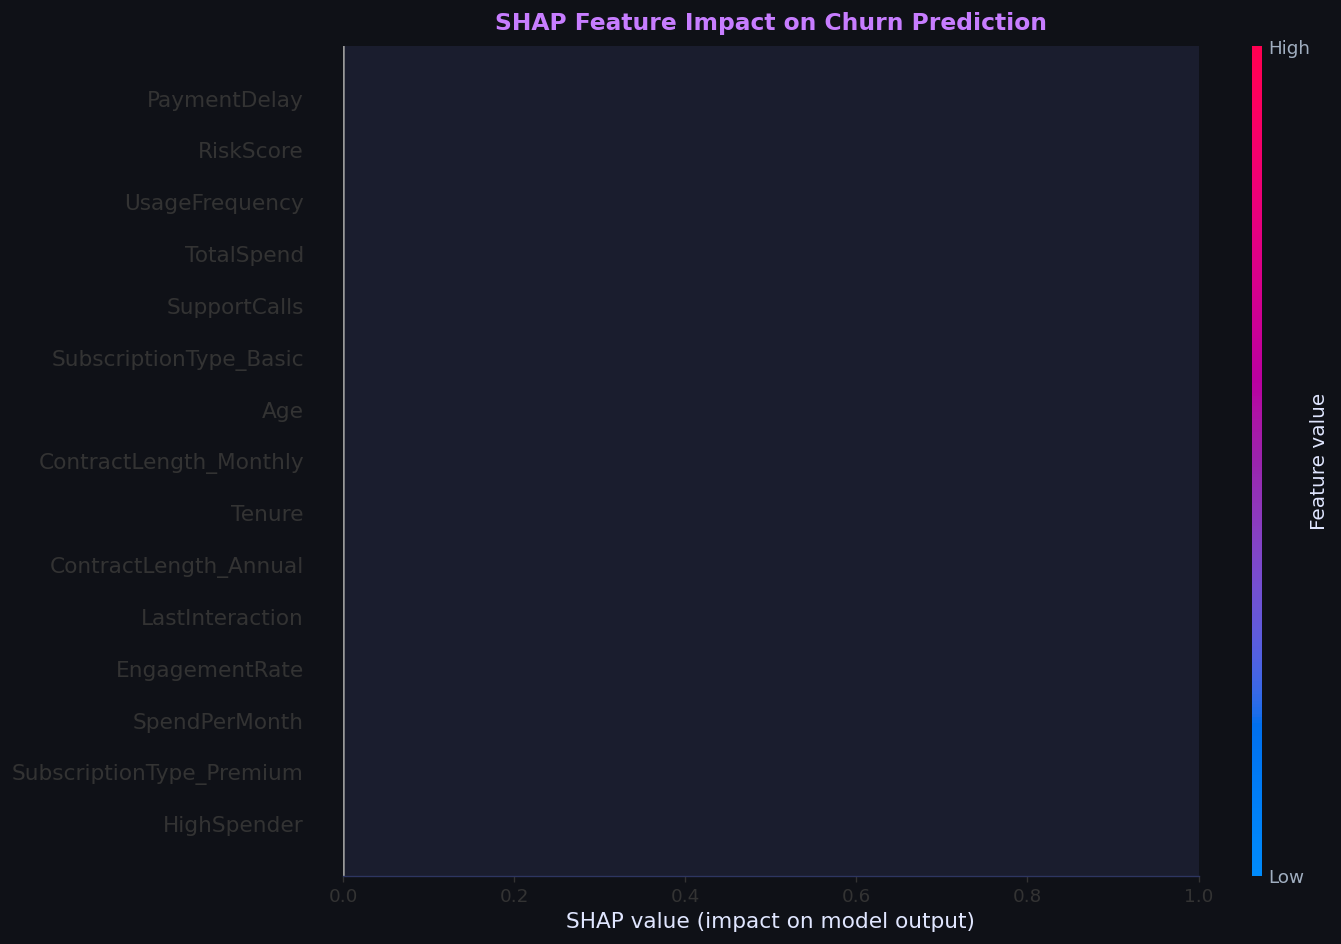

In [27]:
shap.summary_plot(sv, X_test_df, plot_type='beeswarm',
    show=False, max_display=15, plot_size=(12,8))
plt.title('SHAP Feature Impact on Churn Prediction',
    fontsize=14, color='#c77dff', pad=10)
plt.tight_layout()
plt.savefig('shap_summary.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


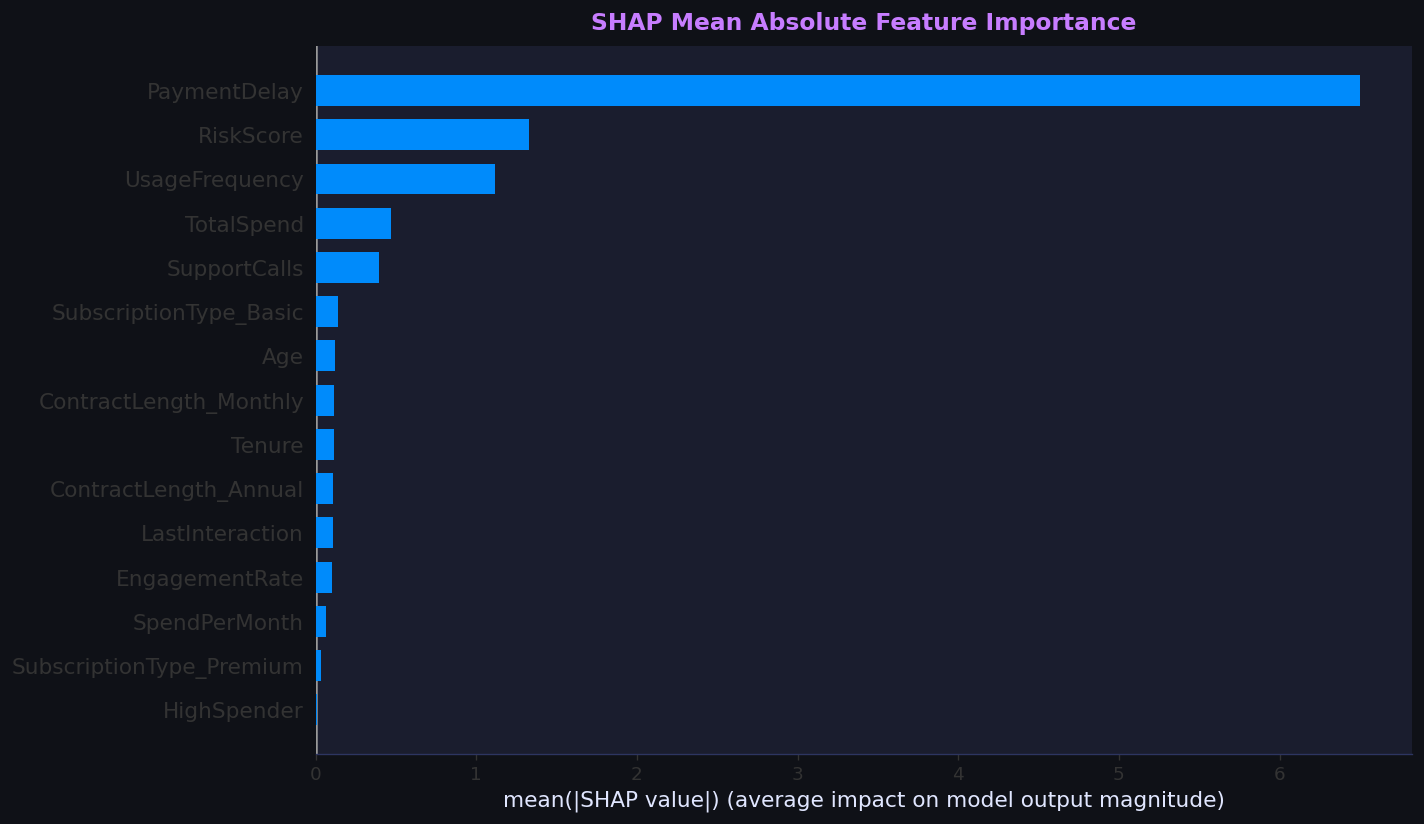

In [28]:
shap.summary_plot(sv, X_test_df, plot_type='bar',
    show=False, max_display=15, plot_size=(12,7))
plt.title('SHAP Mean Absolute Feature Importance',
    fontsize=14, color='#c77dff', pad=10)
plt.tight_layout()
plt.savefig('shap_bar.png', bbox_inches='tight', facecolor='#0f1117')
plt.show()


## 10. Model Saving

In [29]:
pred_final = (test_proba >= OPT_T).astype(int)
artifacts = {
    'pipeline':          best_pipe,
    'optimal_threshold': OPT_T,
    'num_cols':          NUM_COLS,
    'cat_cols':          CAT_COLS,
    'feature_names':     feat_names_trunc,
    'model_name':        'LightGBM (Tuned + SMOTE)',
    'test_roc_auc':      float(roc_auc_score(y_test, test_proba)),
    'test_f1':           float(f1_score(y_test, pred_final)),
    'test_recall':       float(recall_score(y_test, pred_final)),
    'test_precision':    float(precision_score(y_test, pred_final, zero_division=0)),
    'test_accuracy':     float(accuracy_score(y_test, pred_final)),
}
joblib.dump(artifacts, 'churn_model.joblib')

meta = {k:v for k,v in artifacts.items() if k != 'pipeline'}
with open('model_metadata.json','w') as f:
    json.dump(meta, f, indent=2)

print("✅ churn_model.joblib  saved")
print("✅ model_metadata.json saved")
print(f"\n🏆 {artifacts['model_name']}")
print(f"   AUC      = {artifacts['test_roc_auc']:.4f}")
print(f"   F1       = {artifacts['test_f1']:.4f}")
print(f"   Recall   = {artifacts['test_recall']:.4f}")
print(f"   Precision= {artifacts['test_precision']:.4f}")
print(f"   Threshold= {OPT_T:.2f}")


✅ churn_model.joblib  saved
✅ model_metadata.json saved

🏆 LightGBM (Tuned + SMOTE)
   AUC      = 1.0000
   F1       = 0.9976
   Recall   = 0.9964
   Precision= 0.9988
   Threshold= 0.34
